In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("plots.mplstyle")
np.random.seed(42)

In [2]:
import src.heat1D_crank_nicolson_solver as cns

L = 1
Tf = 10
nt = 200000
D = 1
h = 0.1
wanted_r = 1

# Inizializza solver
solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

# Compute impulse response
g = solver.impulse_response()[-1,:]

|---------- Solver info ----------|
Time scale coeff:       1.00e+00
dx:                     7.09e-03
dt:                     5.00e-05
nt:                     200000
nx:                     142
r:                      9.94e-01
h:                      1.00e-01


In [ ]:
import numpy as np
from scipy.optimize import brentq

def f_eigen(x, h, L):
    return x + h * np.tan(x * L)

def trova_radici(h, L, n_radici):
    radici = []
    k = 0
    while len(radici) < n_radici:
        # Per x + h*tan(xL)=0 con h>0 le radici stanno dove tan < 0,
        # cioè in ( (2k+1)π/(2L) , (k+1)π/L )
        left_asym  = (2*k + 1) * np.pi / (2*L)   # asintoto sinistro
        right_zero = (k + 1)   * np.pi / L        # zero di tan
        
        a = left_asym  + 1e-9
        b = right_zero - 1e-9

        try:
            fa, fb = f_eigen(a, h, L), f_eigen(b, h, L)
            if fa * fb < 0:
                root = brentq(f_eigen, a, b, args=(h, L))
                radici.append(root)
        except Exception:
            pass
        k += 1
    return np.array(radici)

radici = trova_radici(h, L, 3)
radici_squared = radici*radici

print(radici)

[1.63199453 4.7335118  7.86669277]
$\lambda_0$ = 1.6319945272148


In [4]:
from scipy.optimize import curve_fit

def func(x, a, q):
    return a*np.exp(-q*x)
    
popt, pcov = curve_fit(func, solver.t_array[100000:], g[100000:], p0=(1,(radici[0]*radici[0])/D))

print(popt)
# a = ampiezza
# q = lambda_0^2 * D  →  lambda_0 = sqrt(q/D)
print(f"q dal fit:         {popt[1]:.6f}")
print(f"lambda_0^2 * D:    {radici[0]**2 * D:.6f}")
print(f"lambda_0 dal fit:  {np.sqrt(popt[1]/D):.6f}")
print(f"lambda_0 teorico:  {radici[0]:.6f}")

[3.14055427 2.66336738]
q dal fit:         2.663367
lambda_0^2 * D:    2.663406
lambda_0 dal fit:  1.631983
lambda_0 teorico:  1.631995


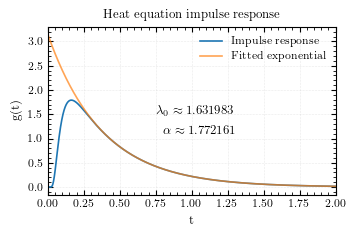

In [13]:
plt.figure()

plt.plot(solver.t_array[:], g[:], label="Impulse response")
plt.plot(solver.t_array[:], func(solver.t_array[:],*popt), label="Fitted exponential", alpha = 0.7)
plt.text(0.75,1.5, fr"$\lambda_0 \approx {np.sqrt(popt[1]*D):.6f}$")
plt.text(0.8,1.1, fr"$\alpha \approx {np.sqrt(popt[0]):.6f}$")

plt.legend()
#plt.ylim([0,1.5])
plt.xlim([0,2])
plt.grid()
plt.title("Heat equation impulse response")

plt.xlabel("t")
plt.ylabel("g(t)")
plt.minorticks_on()
plt.savefig("assets/funzione_trasferimento_risposta_impulso.pdf")
plt.show()

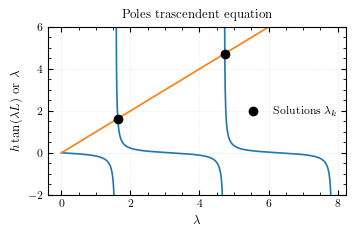

In [6]:
epsilon = 0.001
x_array_plot_1 = np.linspace(0,np.pi/2-epsilon,1000)
x_array_plot_2 = np.linspace(np.pi/2+epsilon,3/2*np.pi-epsilon,1000)
x_array_plot_3 = np.linspace(3*np.pi/2+epsilon,5/2*np.pi-epsilon,1000)

plt.figure()   

plt.plot(x_array_plot_1, -h*np.tan(x_array_plot_1*L), color="C0")
plt.plot(x_array_plot_2, -h*np.tan(x_array_plot_2*L), color="C0")
plt.plot(x_array_plot_3, -h*np.tan(x_array_plot_3*L), color="C0")

plt.plot(np.linspace(0,5/2*np.pi-epsilon,1000),np.linspace(0,5/2*np.pi-epsilon,1000), color="C1")

plt.scatter(radici[0], radici[0], c="k", zorder=3, label=r"Solutions $\lambda_k$")
plt.scatter(radici[1], radici[1], c="k", zorder=3)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$h\tan(\lambda L)$ or $\lambda$")
plt.title("Poles trascendent equation")
plt.grid()
plt.minorticks_on()
plt.legend()
plt.ylim([-2,6])
plt.savefig("assets/trascendi_mident_equation.pdf")